# Max-ent entropy bound: sigma x nt (seed 900)
Runs `*_pf_term_maxent` (11-18: sigma 1/2/3.5/5, both models; 11-19: scat34d at the paper's sigma^2 = 0.1/0.25/2.5/5.5, nt 27500 and 85000 done) + `*_pf_term_fast` (11-17). Plotting code: `viz_maxent_bound.py`.

In [1]:
import sys, traceback
sys.path.insert(0, ".")
import viz_maxent_bound as v
%matplotlib inline

def show(f, *a):
    try:
        f(*a)
    except Exception:
        traceback.print_exc()

rows = v.load_rows()
print(len(rows), "runs")
for r in sorted(rows, key=lambda r: (r["model"], r["sigma"], r["nt"])):
    print(f'{r["model"]:16s} sigma {r["sigma"]:<8g} sigma^2 {r["sigma"]**2:<6.3g} nt {r["nt"]:6d}  '
          f'sigma^2/nt {r["sigma"]**2 / r["nt"]:.2e}  bound {r["H_bound"]:9.2f}  non-finite {r["n_nonfinite"]}')

24 runs
B+Scat4          sigma 1        sigma^2 1      nt  27500  sigma^2/nt 3.64e-05  bound  -1134.86  non-finite 0
B+Scat4          sigma 1        sigma^2 1      nt 110000  sigma^2/nt 9.09e-06  bound  -1163.50  non-finite 0
B+Scat4          sigma 2        sigma^2 4      nt  27500  sigma^2/nt 1.45e-04  bound  -1053.46  non-finite 0
B+Scat4          sigma 2        sigma^2 4      nt 110000  sigma^2/nt 3.64e-05  bound  -1127.58  non-finite 0
B+Scat4          sigma 3.5      sigma^2 12.2   nt  27500  sigma^2/nt 4.45e-04  bound   -995.58  non-finite 0
B+Scat4          sigma 3.5      sigma^2 12.2   nt 110000  sigma^2/nt 1.11e-04  bound  -1069.54  non-finite 0
B+Scat4          sigma 5        sigma^2 25     nt  55000  sigma^2/nt 4.55e-04  bound   -995.62  non-finite 0
B+Scat4          sigma 5        sigma^2 25     nt 110000  sigma^2/nt 2.27e-04  bound  -1020.58  non-finite 0
scat34d (final)  sigma 0.316228 sigma^2 0.1    nt  27500  sigma^2/nt 3.64e-06  bound  -1219.96  non-finite 0
scat34d (fi

### 1. More steps lower the bound at every sigma (not converged in nt)

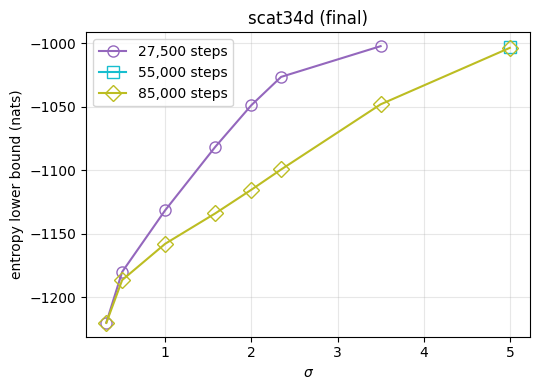

In [2]:
show(v.fig_bound_vs_sigma, rows)

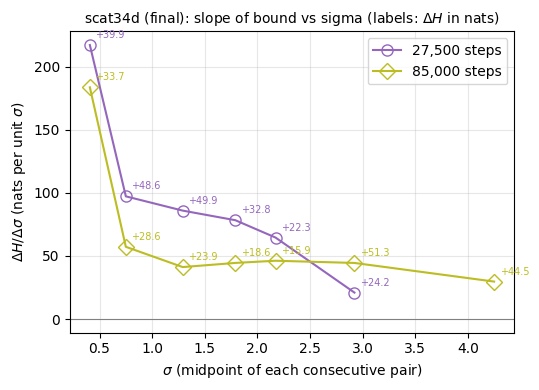

In [3]:
# change of the bound between neighbouring sigma at fixed nt, per unit sigma (labels: Delta H in nats); -> 0 = flat
show(v.fig_delta_vs_sigma, rows)

### 2. Bound vs step size, straight line to h = 0

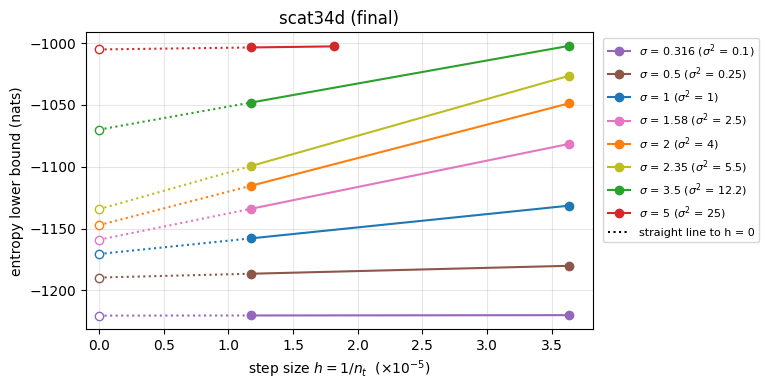

In [4]:
show(v.fig_bound_vs_h, rows)

### 2b. Bound vs sigma with the step error removed (h -> 0 from the two nt per sigma)
Straight line in h = 1/nt through the two runs of each sigma: H(h->0) = (r H(nt2) - H(nt1)) / (r - 1), r = nt2/nt1. Assumes the step error is linear in h (not tested: needs a 3rd nt). Sigmas with one nt only are listed below the table.

scat34d (final): h -> 0 value from the two nt (nats, d = 256)
   sigma sigma^2     nt1     nt2    H(nt1)    H(nt2)   H(h->0) H(h->0)-H(nt2)
  0.3162     0.1   27500   85000  -1219.96  -1220.23  -1220.35          -0.13
     0.5    0.25   27500   85000  -1180.05  -1186.48  -1189.55          -3.07
       1       1   27500   85000  -1131.43  -1157.86  -1170.50         -12.64
   1.581     2.5   27500   85000  -1081.49  -1133.93  -1159.01         -25.08
       2       4   27500   85000  -1048.68  -1115.30  -1147.17         -31.86
   2.345     5.5   27500   85000  -1026.39  -1099.35  -1134.25         -34.90
     3.5    12.2   27500   85000  -1002.19  -1048.02  -1069.95         -21.92
       5      25   55000   85000  -1002.63  -1003.51  -1005.12          -1.61


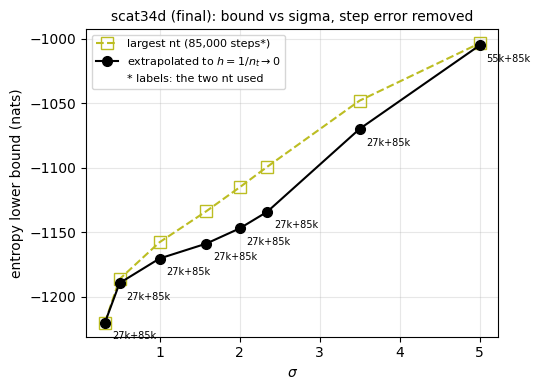

In [5]:
v.print_h0_table(rows)
show(v.fig_bound_h0_vs_sigma, rows)

### 3. Same sigma^2/nt gives the same bound, whatever sigma

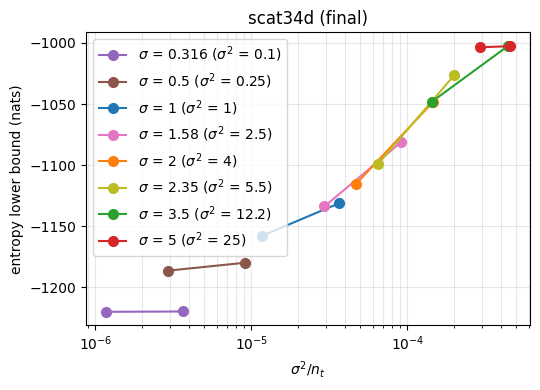

In [6]:
show(v.fig_collapse, rows)

### 4. The two models (B+Scat4 vs final scat34d)

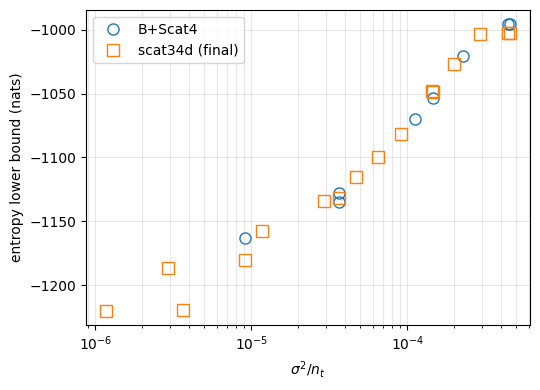

In [7]:
show(v.fig_models, rows)